In [1]:
import numpy as np
import pandas as pd
import os
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
def line_regression(X,w):
   return np.dot(X, w)

In [4]:
def func_loss(X,y,w):
  m = len(X)
  f = line_regression(X,w)
  return (1/2*m) * np.sum((f-y)**2)

In [5]:
def gradient_step(X, y, w, learning_rate):
  m = len(y)
  f = line_regression(X,w)
  grad = (X.T@(f-y))/m
  w-= learning_rate * grad
  return w

In [6]:
def gradient(X,y,learning_rate, num_iter, eps):
  ones = np.ones((X.shape[0],1))
  X = np.hstack((ones,X))
  w = np.zeros(X.shape[1])
  loss =func_loss(X,y,w)
  loss_history = [loss]

  for _ in range(num_iter):
      w-gradient_step(X,y,w,learning_rate)

      loss = func_loss(X,y,w)
      if abs(loss - loss_history[-1]) <eps:
        loss_history.append(loss)
        break
      loss_history.append(loss)
  return w

In [7]:
df = pd.read_csv(("/content/Housing.csv"))

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [9]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [12]:
df[df.duplicated(keep = False)]

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus


In [13]:
df = df.replace({'yes': 1, 'no': 0})

/tmp/ipykernel_1099/2830350339.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace({'yes': 1, 'no': 0})


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    int64 
 6   guestroom         545 non-null    int64 
 7   basement          545 non-null    int64 
 8   hotwaterheating   545 non-null    int64 
 9   airconditioning   545 non-null    int64 
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    int64 
 12  furnishingstatus  545 non-null    object
dtypes: int64(12), object(1)
memory usage: 55.5+ KB


In [15]:
print(df['furnishingstatus'].unique())

['furnished' 'semi-furnished' 'unfurnished']


In [16]:
df['furnishingstatus_num'] = df['furnishingstatus'].map({'unfurnished': 0, 'semi-furnished': 1, 'furnished': 2})

In [17]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,furnishingstatus_num
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished,2
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished,2
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished,2
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,1,0,1,0,0,2,0,unfurnished,0
541,1767150,2400,3,1,1,0,0,0,0,0,0,0,semi-furnished,1
542,1750000,3620,2,1,1,1,0,0,0,0,0,0,unfurnished,0
543,1750000,2910,3,1,1,0,0,0,0,0,0,0,furnished,2


In [18]:
df = df.drop(columns=['furnishingstatus'])

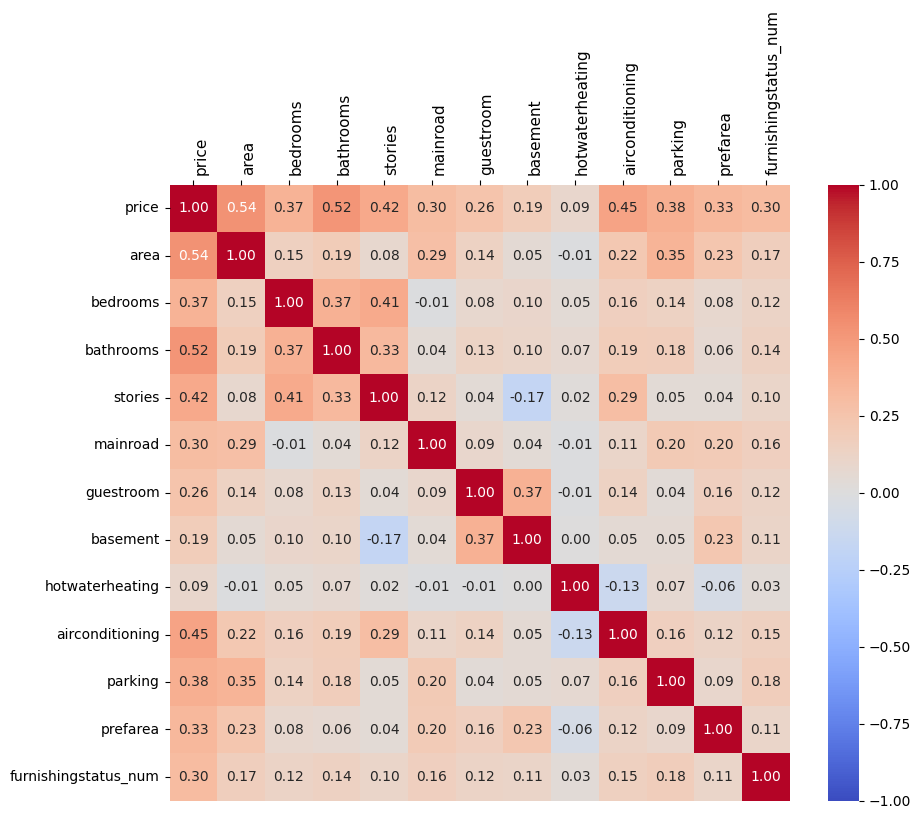

In [19]:
cor_matrix = df.corr()
plt.figure(figsize=(10, 8))

sns.heatmap(
    cor_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1, vmax=1
)

plt.gca().xaxis.tick_top()
plt.gca().xaxis.set_label_position('top')
plt.xticks(rotation=90, ha='left', fontsize=11)
plt.show()

In [20]:

df_copy = df.copy()
columns = ['price', 'area', 'bedrooms', 'bathrooms','stories','mainroad','guestroom','airconditioning','parking','prefarea','furnishingstatus_num']
scaler = StandardScaler()
df_copy[columns] = scaler.fit_transform(df_copy[columns])

In [21]:
df_copy

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_num
0,4.566365,1.046726,1.403419,1.421812,1.378217,0.405623,-0.465315,0,0,1.472618,1.517692,1.804941,1.406286
1,4.004484,1.757010,1.403419,5.405809,2.532024,0.405623,-0.465315,0,0,1.472618,2.679409,-0.554035,1.406286
2,4.004484,2.218232,0.047278,1.421812,0.224410,0.405623,-0.465315,1,0,-0.679063,1.517692,1.804941,0.091662
3,3.985755,1.083624,1.403419,1.421812,0.224410,0.405623,-0.465315,1,0,1.472618,2.679409,1.804941,1.406286
4,3.554979,1.046726,1.403419,-0.570187,0.224410,0.405623,2.149083,1,0,1.472618,1.517692,-0.554035,1.406286
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,-1.576868,-0.991879,-1.308863,-0.570187,-0.929397,0.405623,-0.465315,1,0,-0.679063,1.517692,-0.554035,-1.222962
541,-1.605149,-1.268613,0.047278,-0.570187,-0.929397,-2.465344,-0.465315,0,0,-0.679063,-0.805741,-0.554035,0.091662
542,-1.614327,-0.705921,-1.308863,-0.570187,-0.929397,0.405623,-0.465315,0,0,-0.679063,-0.805741,-0.554035,-1.222962
543,-1.614327,-1.033389,0.047278,-0.570187,-0.929397,-2.465344,-0.465315,0,0,-0.679063,-0.805741,-0.554035,1.406286


In [23]:
X = df_copy[['area', 'bedrooms', 'bathrooms','stories','mainroad','guestroom','airconditioning','parking','prefarea','furnishingstatus_num']].values
y = df_copy['price'].values
learning_rate = 0.001
num_iter = 1000000
eps = 1e-12
w = gradient(X,y,learning_rate, num_iter, eps)
print(f'Gradient Descent: {w.round(4)}')

Gradient Descent: [0.     0.2744 0.0625 0.2801 0.1852 0.0799 0.0918 0.1992 0.1378 0.1574
 0.0956]


In [24]:
ones = np.ones((X.shape[0],1))
X = np.hstack((ones,X))
w_analytical = np.linalg.inv(X.T@X)@X.T@y
print(f'Analytical Solution:{w_analytical.round(4)}')

Analytical Solution:[0.     0.2744 0.0625 0.2801 0.1852 0.0799 0.0918 0.1992 0.1378 0.1574
 0.0956]


Intercepr: -0.01043722446032364
Coefficient: ['0.0000', '0.2705', '0.0745', '0.2761', '0.1707', '0.0767', '0.1087', '0.1937', '0.1535', '0.1623', '0.0815']
Training MAE: 0.4148, MSE: 0.3273, r2: 0.6665
Test MAE: 0.4585, MSE: 0.3743, r2: 0.6474


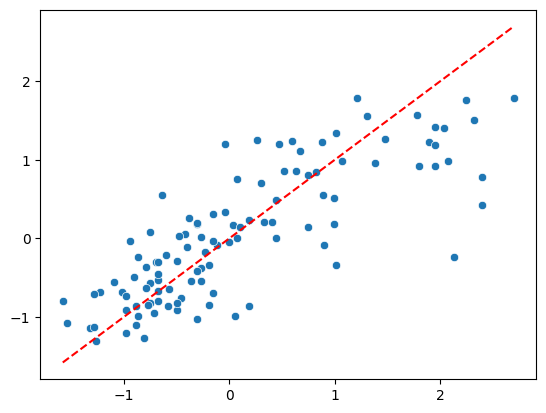

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 20)

lin_reg_model = LinearRegression()
lin_reg_model.fit(X_train, y_train)

y_train_pred = lin_reg_model.predict(X_train)
y_test_pred = lin_reg_model.predict(X_test)

print(f'Intercepr: {lin_reg_model.intercept_}')
print(f'Coefficient: {[f'{c:.4f}' for c in lin_reg_model.coef_]}')

train_MAE = mean_absolute_error(y_train, y_train_pred)
train_MSE = mean_squared_error(y_train, y_train_pred)
train_R2 = r2_score(y_train, y_train_pred)

print(f'Training MAE: {train_MAE:.4f}, MSE: {train_MSE:.4f}, r2: {train_R2:.4f}')

test_MAE = mean_absolute_error(y_test, y_test_pred)
test_MSE = mean_squared_error(y_test, y_test_pred)
test_R2 = r2_score(y_test, y_test_pred)

print(f'Test MAE: {test_MAE:.4f}, MSE: {test_MSE:.4f}, r2: {test_R2:.4f}')
sns.scatterplot(x=y_test, y=y_test_pred)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],'r--')